# 🎯 [K10] 군 생활 정보 챗봇 - 전입 병사 생활 안내 챗봇 구현
### Google Colab 실습 환경 (병영생활·상담 / Level 1)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/edunlab/milicontent2/blob/main/uploads/K10/K10_solution.ipynb)

---

## 📌 1. 프로젝트 개요 및 배경

| 항목 | 내용 |
| :--- | :--- |
| **과정 분류** | 병영생활·상담 (Level 1) |
| **학습 소요 시간** | 10개 미션 (5일 / 총 20.0시간) |
| **환경 사양** | Python 3.10+, numpy, pandas, matplotlib, scipy, scikit-learn |

### 📖 프로젝트 목표
전입 병사는 일과, 휴가, 외출, 복지시설, 의무, 보안 등 궁금한 것이 많지만 물어볼 때마다 선임이나 행정반을 찾기 어렵습니다. 이 프로젝트에서는 가상 한빛대대의 생활 FAQ를 의도(질문 종류)별로 정리하고, 키워드 규칙 Baseline에서 TF-IDF 의도 분류로 개선한 뒤, 정확도와 혼동표로 평가합니다. 이어서 인사·되묻기·모르는 질문 안내를 갖춘 대화 흐름과 답변 템플릿을 만들고, 생성형 AI에 넣을 시스템 프롬프트까지 자동 생성하여, 모르는 질문에는 지어내지 않고 담당 부서를 안내하는 '전입 병사 생활 안내 챗봇'을 구현합니다.

> **⚠️ [교육용 가상 데이터셋 원칙]**
> - 본 실습의 모든 데이터(공지, 규정, 일정 등)는 보안 규정을 준수하여 **코드 내 난수 및 가상 시나리오로 생성**됩니다.
> - 실제 부대 작전, 군사 기밀 및 개인 식별 정보는 일체 포함되지 않습니다.

---



In [1]:
# ============================================================================
# [Google Colab 환경 설정] 필수 라이브러리 설치 및 임포트
# ============================================================================
!pip install -q numpy pandas matplotlib scipy scikit-learn

import os
import sys
import time
import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 그래프 영문 폰트 기본 설정 (환경 독립성 보장)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print(f"실행 환경 준비 완료 (Python {sys.version.split()[0]})")


실행 환경 준비 완료 (Python 3.14.10)


---

## 🎯 미션 01. 생활 FAQ 의도별로 정리하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **가상 생활 FAQ를 의도별로 정리하고 학습용·시험용 질문으로 나눕니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **의도 15개마다 이름, 담당 부서, 답변, 질문 예시 6개를 표로 확인하고 앞 4개는 학습용, 뒤 2개는 시험용으로 분석하여 역할과 범위를 구분하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `의도 구성표, 학습·시험 질문 수, 구조 점검 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 데이터 구조화 — 의도·답변·담당 부서를 갖춘 FAQ를 만들고 학습·시험 질문을 구분했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(의도 구성표, 학습·시험 질문 수, 구조 점검 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [2]:
"""가상 한빛대대 전입 병사 생활 FAQ를 의도(질문 종류)별로 구조화하고, 학습용·시험용 질문으로 나눠 구성을 점검한다."""
import pandas as pd

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

rows = []
for code, name, dept, answer, examples in FAQ:
    rows.append({"의도": code, "이름": name, "담당 부서": dept, "학습 질문": len(examples[:4]),
                 "시험 질문": len(examples[4:]), "답변 글자수": len(answer)})
df = pd.DataFrame(rows)
print(df.to_string(index=False))

all_q = [q for f in FAQ for q in f[4]]
print(f"\n의도 {len(df)}개, 질문 예시 {len(all_q)}개 (학습 {len(TRAIN)} + 시험 {len(TEST)})")
print(f"답변 평균 {df['답변 글자수'].mean():.0f}자, 담당 부서 {df['담당 부서'].nunique()}곳")
print("질문 중복:", "없음" if len(set(all_q)) == len(all_q) else "있음")
print("의도별 질문 수 균형:", "정상" if df["학습 질문"].nunique() == 1 and df["시험 질문"].nunique() == 1 else "불균형")
print("\n학습용과 시험용을 나누는 이유: 외운 질문이 아니라 처음 보는 질문에서 챗봇이 맞히는지 확인하기 위해서다.")


      의도      이름   담당 부서  학습 질문  시험 질문  답변 글자수
schedule   일과 시간  중대 행정반      4      2      65
   leave      휴가  중대 행정반      4      2      75
  outing   외출·외박   당직 계통      4      2      57
    late   복귀 지연    당직사관      4      2      54
   visit      면회  중대 행정반      4      2      64
   phone 휴대전화·전화  중대 행정반      4      2      74
 welfare    복지시설   복지 담당      4      2      55
    meal      식사   취사 담당      4      2      81
 medical   진료·의무     의무실      4      2      66
security   보안·촬영   보안 담당      4      2      80
 account 계정·비밀번호 정보보호 담당      4      2      73
 selfdev    자기개발 정훈교육 담당      4      2      62
 counsel   고충·상담 병영생활상담관      4      2      57
    room  생활관·청소     분대장      4      2      66
  supply  보급품·세탁   군수 담당      4      2      84

의도 15개, 질문 예시 90개 (학습 60 + 시험 30)
답변 평균 68자, 담당 부서 12곳
질문 중복: 없음
의도별 질문 수 균형: 정상

학습용과 시험용을 나누는 이유: 외운 질문이 아니라 처음 보는 질문에서 챗봇이 맞히는지 확인하기 위해서다.


---

## 🎯 미션 02. 장병 질문 말투 정리하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **장병이 쓰는 말투가 섞인 질문을 분류하기 좋게 정리하는 함수를 만듭니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **웃음 표시, 특수문자, 반복 공백, '언제·어떻게·하나요' 같은 질문 투 말을 걸러 내는 함수를 만들고 정리 전후 글자 수와 단어 종류를 비교 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `질문 정리 함수, 정리 전후 비교표` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 질문 전처리 — 질문을 정리하면서 핵심 단어는 지키고 불필요한 말만 걸러 냈는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(질문 정리 함수, 정리 전후 비교표)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [3]:
"""장병이 실제로 쓰는 말투(웃음 표시·특수문자·질문 투 말)가 섞인 질문을 정리하는 함수를 만들고 정리 전후를 비교한다."""
import re
import numpy as np

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

RAW = ["휴가 신청은 언제까지 해야 하나요?!", "점호 몇 시에 하나요ㅋㅋㅋ", "외출 어떻게 나가요~~", "비밀번호 알려주세요ㅠㅠ",
       "PX 언제 열어요?", "면회  신청   어디서 하나요...", "의무실 어디 있나요??", "자격증 응시료 지원돼요?"]
print("[정리 전 -> 정리 후]")
for q in RAW:
    print(f" {q!r:32} -> {normalize(q)!r}")

before = np.mean([len(q) for q, _ in TRAIN])
after = np.mean([len(normalize(q)) for q, _ in TRAIN])
changed = sum(normalize(q) != q for q, _ in TRAIN)
voc_b = len({w for q, _ in TRAIN for w in q.split()})
voc_a = len({w for q, _ in TRAIN for w in normalize(q).split()})
empty = [q for q, _ in TRAIN + TEST if not normalize(q)]
print(f"\n학습 질문 {len(TRAIN)}개 평균 글자수 {before:.1f} -> {after:.1f}")
print(f"정리로 달라진 질문 {changed}개, 단어 종류 {voc_b} -> {voc_a}")
print("정리 후 빈 문장:", "없음" if not empty else empty)
print("정리 원칙: 의미 있는 단어(휴가, 점호, PX)는 남기고, 모든 질문에 붙는 말(언제, 어떻게, 하나요)은 뺀다.")


[정리 전 -> 정리 후]
 '휴가 신청은 언제까지 해야 하나요?!'           -> '휴가 신청은'
 '점호 몇 시에 하나요ㅋㅋㅋ'                 -> '점호'
 '외출 어떻게 나가요~~'                   -> '외출 나가요'
 '비밀번호 알려주세요ㅠㅠ'                   -> '비밀번호'
 'PX 언제 열어요?'                     -> 'PX 열어요'
 '면회  신청   어디서 하나요...'            -> '면회 신청'
 '의무실 어디 있나요??'                   -> '의무실'
 '자격증 응시료 지원돼요?'                  -> '자격증 응시료 지원'

학습 질문 60개 평균 글자수 14.7 -> 10.2
정리로 달라진 질문 51개, 단어 종류 173 -> 154
정리 후 빈 문장: 없음
정리 원칙: 의미 있는 단어(휴가, 점호, PX)는 남기고, 모든 질문에 붙는 말(언제, 어떻게, 하나요)은 뺀다.


---

## 🎯 미션 03. 규칙 기반 의도 분류 만들기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **핵심 키워드로 의도를 정하는 규칙 기반 Baseline을 만들고 한계를 확인합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **의도별 키워드 사전으로 질문의 의도를 고르는 함수를 만들어 시험 질문 정확도를 계산 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `규칙 분류 함수, 정확도, 분류 실패 목록` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 기본 모델 구현 — Baseline 분류기를 구현하고 정확도와 한계를 확인했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(규칙 분류 함수, 정확도, 분류 실패 목록)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [4]:
"""질문에 들어 있는 핵심 단어로 의도를 정하는 규칙 기반 Baseline 분류기를 만들고 시험 질문 정확도와 한계를 확인한다."""
import re
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

gold = [g for _, g in TEST]
pred = [rule_classify(q) for q, _ in TEST]
acc = accuracy(pred, gold)
none_n = sum(p is None for p in pred)
wrong = [(q, g, p) for (q, g), p in zip(TEST, pred) if p is not None and p != g]
print(f"규칙 기반 Baseline 정확도: {acc:.0%} ({sum(p == g for p, g in zip(pred, gold))}/{len(TEST)})")
print(f"키워드가 하나도 없어 분류 못 한 질문 {none_n}개, 엉뚱한 의도로 분류 {len(wrong)}개\n")

rows = []
for code in INTENT_IDS:
    idx = [i for i, g in enumerate(gold) if g == code]
    rows.append({"의도": INTENT_NAME[code], "정답": sum(pred[i] == code for i in idx), "시험 질문": len(idx)})
print(pd.DataFrame(rows).to_string(index=False))

print("\n[분류 못 한 질문 예]")
for (q, g), p in zip(TEST, pred):
    if p is None:
        print(f" {q}  (정답 {INTENT_NAME[g]})")
    if sum(1 for x in pred[:TEST.index((q, g)) + 1] if x is None) >= 6:
        break
print("\n한계: 키워드 사전에 없는 표현('일어나야', '도서관')은 놓치고, 사전을 늘릴수록 관리가 어려워진다.")


규칙 기반 Baseline 정확도: 43% (13/30)
키워드가 하나도 없어 분류 못 한 질문 16개, 엉뚱한 의도로 분류 1개

     의도  정답  시험 질문
  일과 시간   1      2
     휴가   2      2
  외출·외박   2      2
  복귀 지연   1      2
     면회   2      2
휴대전화·전화   1      2
   복지시설   0      2
     식사   1      2
  진료·의무   0      2
  보안·촬영   0      2
계정·비밀번호   1      2
   자기개발   1      2
  고충·상담   0      2
 생활관·청소   1      2
 보급품·세탁   0      2

[분류 못 한 질문 예]
 아침에 몇 시에 일어나야 해요  (정답 일과 시간)
 휴대폰 보관은 어디에 하나요  (정답 휴대전화·전화)
 운동하려면 어디로 가야 해요  (정답 복지시설)
 도서관은 언제 열어요  (정답 복지시설)
 점심은 몇 시에 나와요  (정답 식사)
 병원에 가야 할 것 같아요  (정답 진료·의무)

한계: 키워드 사전에 없는 표현('일어나야', '도서관')은 놓치고, 사전을 늘릴수록 관리가 어려워진다.


---

## 🎯 미션 04. TF-IDF로 의도 분류 개선하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **TF-IDF 유사도로 의도를 분류하여 Baseline보다 개선합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **의도마다 이름·답변·학습 질문을 한 문서로 묶어 TF-IDF 벡터로 바꾸고, 질문과 가장 비슷한 의도를 비교 분석하여 최적 도구를 선정하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `TF-IDF 분류기, Baseline 비교 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [선택] 모델 고도화 — TF-IDF 분류기를 구현하고 Baseline 대비 개선을 확인했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(TF-IDF 분류기, Baseline 비교 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [5]:
"""의도별 예시 질문을 TF-IDF 벡터로 바꿔 가장 비슷한 의도를 고르는 분류기를 만들고 규칙 기반 Baseline과 정확도를 비교한다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

gold = [g for _, g in TEST]
rule_acc = accuracy([rule_classify(q) for q, _ in TEST], gold)
clf = TfidfClassifier()
pred = [clf.predict(q)[0] for q, _ in TEST]
tf_acc = accuracy(pred, gold)
top2 = np.mean([g in [i for i, _ in clf.top(q, 2)] for q, g in TEST])
print(f"규칙 기반 Baseline {rule_acc:.0%}  ->  TF-IDF 분류 {tf_acc:.0%}  (후보 2개 안에 정답 {top2:.0%})")

print("\n[예시 질문의 분류 결과]")
for q in ["첫 휴가는 언제 나갈 수 있어요", "핸드폰 언제 줘요", "사진 찍어도 됨?", "어디가 아프면 누구한테 말해요"]:
    (i1, s1), (i2, s2) = clf.top(q, 2)
    print(f" {q} -> 1위 {INTENT_NAME[i1]}({s1:.2f}), 2위 {INTENT_NAME[i2]}({s2:.2f})")

print("\n[의도마다 넣어 준 학습 질문 수에 따른 정확도]")
rows = []
for n in [0, 1, 2, 3, 4]:
    c = TfidfClassifier(n_train=n)
    rows.append({"학습 질문 수": n, "정확도": f"{accuracy([c.predict(q)[0] for q, _ in TEST], gold):.0%}"})
print(pd.DataFrame(rows).to_string(index=False))
print("예시 질문이 없어도 이름·답변 문장만으로 어느 정도 맞히고, 예시를 넣으면 올라간다. 다만 시험 질문이 30개뿐이라 1문항(3%p) 차이는 우연일 수 있다.")


규칙 기반 Baseline 43%  ->  TF-IDF 분류 77%  (후보 2개 안에 정답 80%)

[예시 질문의 분류 결과]
 첫 휴가는 언제 나갈 수 있어요 -> 1위 휴가(0.34), 2위 보급품·세탁(0.07)
 핸드폰 언제 줘요 -> 1위 휴대전화·전화(0.22), 2위 식사(0.01)
 사진 찍어도 됨? -> 1위 보안·촬영(0.25), 2위 생활관·청소(0.02)
 어디가 아프면 누구한테 말해요 -> 1위 진료·의무(0.17), 2위 복귀 지연(0.16)

[의도마다 넣어 준 학습 질문 수에 따른 정확도]
 학습 질문 수 정확도
       0 70%
       1 77%
       2 80%
       3 80%
       4 77%
예시 질문이 없어도 이름·답변 문장만으로 어느 정도 맞히고, 예시를 넣으면 올라간다. 다만 시험 질문이 30개뿐이라 1문항(3%p) 차이는 우연일 수 있다.


---

## 🎯 미션 05. 정확도와 혼동표로 평가하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **정확도, 의도별 정밀도·재현율, 혼동표로 분류 성능을 평가합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **시험 질문으로 전체 정확도와 의도별 정밀도·재현율·F1을 계산하고, 혼동표에서 틀린 칸만 모아 가장 헷갈리는 의도 쌍을 찾습니다 과정을 진행하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `성능 평가표, 혼동표, 오분류 원인 정리` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 성능 평가 — 여러 지표와 혼동표로 성능을 평가하고 오분류 원인을 찾았는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(성능 평가표, 혼동표, 오분류 원인 정리)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [6]:
"""TF-IDF 의도 분류기를 정확도·의도별 재현율·혼동표로 평가하고 가장 헷갈리는 의도 쌍을 찾는다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import precision_recall_fscore_support

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

clf = TfidfClassifier()
gold = [g for _, g in TEST]
pred = [clf.predict(q)[0] for q, _ in TEST]
acc = accuracy(pred, gold)
p, r, f, _ = precision_recall_fscore_support(gold, pred, labels=INTENT_IDS, zero_division=0)
rep = pd.DataFrame({"의도": [INTENT_NAME[i] for i in INTENT_IDS], "정밀도": p.round(2), "재현율": r.round(2), "F1": f.round(2)})
print(rep.to_string(index=False))
print(f"\n전체 정확도 {acc:.0%} ({sum(a == b for a, b in zip(pred, gold))}/{len(gold)}), 평균 F1 {f.mean():.2f}")
print("목표 70% 이상:", "목표 달성" if acc >= 0.7 else "목표 미달")

cm = pd.crosstab(pd.Series([INTENT_NAME[g] for g in gold], name="정답"), pd.Series([INTENT_NAME[x] for x in pred], name="예측"))
wrong_cm = cm.copy()
for k in wrong_cm.index:
    if k in wrong_cm.columns:
        wrong_cm.loc[k, k] = 0
pairs = wrong_cm.stack()
pairs = pairs[pairs > 0].sort_values(ascending=False)
print("\n[혼동표에서 틀린 칸만 (정답 -> 예측)]")
for (a, b), n in pairs.items():
    print(f" {a} -> {b}: {n}건")
print("\n[틀린 질문 예]")
for (q, g), x in list(zip(TEST, pred)):
    if g != x:
        print(f" {q}  (정답 {INTENT_NAME[g]}, 예측 {INTENT_NAME[x]})")


     의도  정밀도  재현율   F1
  일과 시간 1.00  0.5 0.67
     휴가 1.00  1.0 1.00
  외출·외박 1.00  1.0 1.00
  복귀 지연 0.67  1.0 0.80
     면회 0.67  1.0 0.80
휴대전화·전화 0.67  1.0 0.80
   복지시설 0.00  0.0 0.00
     식사 0.50  1.0 0.67
  진료·의무 0.00  0.0 0.00
  보안·촬영 1.00  0.5 0.67
계정·비밀번호 0.67  1.0 0.80
   자기개발 1.00  1.0 1.00
  고충·상담 1.00  1.0 1.00
 생활관·청소 1.00  1.0 1.00
 보급품·세탁 1.00  0.5 0.67

전체 정확도 77% (23/30), 평균 F1 0.72
목표 70% 이상: 목표 달성

[혼동표에서 틀린 칸만 (정답 -> 예측)]
 보급품·세탁 -> 복지시설: 1건
 보안·촬영 -> 휴대전화·전화: 1건
 복지시설 -> 계정·비밀번호: 1건
 복지시설 -> 면회: 1건
 일과 시간 -> 식사: 1건
 진료·의무 -> 복귀 지연: 1건
 진료·의무 -> 식사: 1건

[틀린 질문 예]
 아침에 몇 시에 일어나야 해요  (정답 일과 시간, 예측 식사)
 운동하려면 어디로 가야 해요  (정답 복지시설, 예측 면회)
 도서관은 언제 열어요  (정답 복지시설, 예측 계정·비밀번호)
 병원에 가야 할 것 같아요  (정답 진료·의무, 예측 복귀 지연)
 예방접종은 언제 하나요  (정답 진료·의무, 예측 식사)
 휴대폰 카메라 써도 돼요  (정답 보안·촬영, 예측 휴대전화·전화)
 세탁실은 언제 쓸 수 있나요  (정답 보급품·세탁, 예측 복지시설)


---

## 🎯 미션 06. 대화 흐름 설계하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **인사, 되묻기, 모르는 질문 안내를 가르는 대화 흐름을 설계합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **인사·감사·종료 말을 먼저 가려내고, 최소 유사도보다 낮으면 '모름', 1·2위 점수가 비슷하면 '되묻기', 아니면 '답변'으로 판정하는 함수를 제작하고 안정성을 확보하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `대화 흐름 판정 함수, 시나리오 결과표, 판정 분포` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 대화 흐름 설계 — 질문을 답변·되묻기·모름으로 가르고 모르는 질문에 지어내지 않게 했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(대화 흐름 판정 함수, 시나리오 결과표, 판정 분포)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [7]:
"""인사·감사·종료, 되묻기, 모르는 질문 안내를 가르는 대화 흐름 판정 함수를 만들고 대화 시나리오로 동작을 확인한다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

# ---- 공통: 대화 흐름 (인사 -> 의도 분류 -> 되묻기/모름 안내/답변) ----
GREET = ["안녕", "안녕하세요", "반갑", "처음 왔", "전입 왔", "하이"]
THANKS = ["감사", "고마워", "고맙", "수고"]
BYE = ["종료", "그만", "잘 가", "다음에"]
THRESH, MARGIN = 0.15, 0.04      # 최소 유사도, 1·2위 점수 차이 기준
GENERAL_DEPT = "중대 행정반 또는 분대장"


def decide(clf, q, thresh=THRESH, margin=MARGIN):
    """('greet'|'thanks'|'bye'|'answer'|'clarify'|'unknown', 의도, 점수, 후보)"""
    if any(w in q for w in BYE):
        return "bye", None, 0.0, []
    if any(w in q for w in THANKS):
        return "thanks", None, 0.0, []
    top = clf.top(q, 2)
    (i1, s1), (i2, s2) = top[0], top[1]
    if any(w in q for w in GREET) and s1 < 0.25:
        return "greet", None, s1, top
    if s1 < thresh:
        return "unknown", None, s1, top
    if s1 - s2 < margin:
        return "clarify", i1, s1, top
    return "answer", i1, s1, top

clf = TfidfClassifier()
ACTION = {"greet": "인사로 맞이", "thanks": "감사에 답례", "bye": "대화 종료", "answer": "의도의 답변 안내",
          "clarify": "비슷한 두 의도 중 되묻기", "unknown": "담당 부서 안내(모름)"}
SCENARIO = ["안녕하세요 오늘 전입 왔습니다", "휴가 어떻게 신청해요", "개인정비 시간은 언제인가요", "사단장 방문 일정은?",
            "PX 몇 시에 열어요", "전역일이 언제야", "오늘 날씨 어때요", "핸드폰 언제 줘요", "감사합니다", "이만 종료할게요"]
rows = []
for q in SCENARIO:
    kind, intent, score, top = decide(clf, q)
    rows.append({"발화": q, "판정": kind, "의도": INTENT_NAME.get(intent, "-"), "1위 점수": round(score, 2), "챗봇 동작": ACTION[kind]})
print(pd.DataFrame(rows).to_string(index=False))

kinds = [decide(clf, q)[0] for q, _ in TEST]
print(f"\n시험 질문 {len(TEST)}개 판정: " + ", ".join(f"{k} {kinds.count(k)}" for k in ["answer", "clarify", "unknown"]))
bad = [q for q, g in TEST if decide(clf, q)[0] == "answer" and decide(clf, q)[1] != g]
print(f"바로 답했는데 의도가 틀린 질문: {len(bad)}개 (답변 {kinds.count('answer')}개 중)")
print(f"기준: 최소 유사도 {THRESH}, 1·2위 점수 차 {MARGIN}. 점수가 낮으면 모름, 두 의도가 비슷하면 되묻기, 아니면 답변.")
print("원칙: 모르는 질문에 지어낸 답을 하지 않고, 확인할 곳(담당 부서)을 알려 준다.")


              발화      판정      의도  1위 점수          챗봇 동작
안녕하세요 오늘 전입 왔습니다   greet       -   0.15         인사로 맞이
     휴가 어떻게 신청해요  answer      휴가   0.47      의도의 답변 안내
  개인정비 시간은 언제인가요 clarify   일과 시간   0.20 비슷한 두 의도 중 되묻기
     사단장 방문 일정은? unknown       -   0.11   담당 부서 안내(모름)
     PX 몇 시에 열어요  answer    복지시설   0.29      의도의 답변 안내
        전역일이 언제야 unknown       -   0.11   담당 부서 안내(모름)
       오늘 날씨 어때요 unknown       -   0.13   담당 부서 안내(모름)
       핸드폰 언제 줘요  answer 휴대전화·전화   0.22      의도의 답변 안내
           감사합니다  thanks       -   0.00         감사에 답례
        이만 종료할게요     bye       -   0.00          대화 종료

시험 질문 30개 판정: answer 21, clarify 5, unknown 4
바로 답했는데 의도가 틀린 질문: 3개 (답변 21개 중)
기준: 최소 유사도 0.15, 1·2위 점수 차 0.04. 점수가 낮으면 모름, 두 의도가 비슷하면 되묻기, 아니면 답변.
원칙: 모르는 질문에 지어낸 답을 하지 않고, 확인할 곳(담당 부서)을 알려 준다.


---

## 🎯 미션 07. 답변 템플릿 만들기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **판정별 답변 템플릿을 만들어 일정한 형식으로 응답합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **답변은 '[주제] 답변 + 담당 부서 안내'로, 되묻기는 비슷한 두 주제를 보여 주는 형식으로, 모름은 확인할 곳을 알려 주는 형식으로 제작하고 안정성을 확보하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `답변 템플릿, 응답 예시, 형식 점검 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [선택] 응답 형식 설계 — 템플릿으로 일정한 형식의 응답을 만들고 누락 여부를 점검했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(답변 템플릿, 응답 예시, 형식 점검 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [8]:
"""의도별 답변 템플릿(이름·답변·담당 부서 안내)과 되묻기·모름 문구를 만들고, 빈칸이 모두 채워졌는지 점검한다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

# ---- 공통: 대화 흐름 (인사 -> 의도 분류 -> 되묻기/모름 안내/답변) ----
GREET = ["안녕", "안녕하세요", "반갑", "처음 왔", "전입 왔", "하이"]
THANKS = ["감사", "고마워", "고맙", "수고"]
BYE = ["종료", "그만", "잘 가", "다음에"]
THRESH, MARGIN = 0.15, 0.04      # 최소 유사도, 1·2위 점수 차이 기준
GENERAL_DEPT = "중대 행정반 또는 분대장"


def decide(clf, q, thresh=THRESH, margin=MARGIN):
    """('greet'|'thanks'|'bye'|'answer'|'clarify'|'unknown', 의도, 점수, 후보)"""
    if any(w in q for w in BYE):
        return "bye", None, 0.0, []
    if any(w in q for w in THANKS):
        return "thanks", None, 0.0, []
    top = clf.top(q, 2)
    (i1, s1), (i2, s2) = top[0], top[1]
    if any(w in q for w in GREET) and s1 < 0.25:
        return "greet", None, s1, top
    if s1 < thresh:
        return "unknown", None, s1, top
    if s1 - s2 < margin:
        return "clarify", i1, s1, top
    return "answer", i1, s1, top

# ---- 공통: 답변 템플릿 ----
CLOSING = "더 궁금한 점은 {dept}에 확인하세요. (이 안내는 교육용 가상 자료입니다)"
TEMPLATES = {
    "greet": "안녕하세요, 한빛대대 전입 병사 생활 안내 챗봇입니다. 일과, 휴가, 외출, 복지시설, 의무, 보안 등을 물어보세요.",
    "thanks": "도움이 되었다면 다행입니다. 다른 질문이 있으면 편하게 물어보세요.",
    "bye": "안내를 마칩니다. 확인이 필요한 내용은 분대장과 행정반에 문의하세요.",
    "answer": "[{name}] {answer}\n{closing}",
    "clarify": "'{q}'는 [{n1}]과 [{n2}] 중 어느 쪽이 궁금한가요? 한 가지를 골라 다시 물어봐 주세요.",
    "unknown": "질문에 맞는 안내를 찾지 못했습니다. 이 내용은 " + GENERAL_DEPT + "에게 확인해 주세요.",
}


def respond(clf, q, thresh=THRESH, margin=MARGIN):
    kind, intent, score, top = decide(clf, q, thresh, margin)
    if kind in ("greet", "thanks", "bye"):
        return kind, None, TEMPLATES[kind]
    if kind == "unknown":
        return kind, None, TEMPLATES["unknown"]
    if kind == "clarify":
        return kind, intent, TEMPLATES["clarify"].format(q=q, n1=INTENT_NAME[top[0][0]], n2=INTENT_NAME[top[1][0]])
    text = TEMPLATES["answer"].format(name=INTENT_NAME[intent], answer=ANSWER[intent],
                                      closing=CLOSING.format(dept=DEPT[intent]))
    return kind, intent, text

clf = TfidfClassifier()
for q in ["안녕하세요", "기상 시간이 몇 시예요", "외출 때 뭘 보고해요", "개인정비 시간은 언제인가요", "사단장 방문 일정은?", "고맙습니다"]:
    kind, intent, text = respond(clf, q)
    print(f"Q. {q}  [{kind}]\nA. {text}\n")

kinds, leftover, no_dept = [], 0, 0
for q, g in TEST:
    kind, intent, text = respond(clf, q)
    kinds.append(kind)
    leftover += bool(re.search(r"[{}]", text))
    if kind == "answer" and DEPT[intent] not in text:
        no_dept += 1
n_ans = kinds.count("answer")
print(f"시험 질문 {len(TEST)}개 -> 답변 {n_ans}, 되묻기 {kinds.count('clarify')}, 모름 {kinds.count('unknown')}")
print(f"빈칸({{}})이 남은 답변: {leftover}개, 담당 부서 안내가 빠진 답변: {no_dept}개")
print("점검:", "PASS" if leftover == 0 and no_dept == 0 else "FAIL")
print("템플릿을 쓰면 답변 모양이 같아져 읽기 쉽고, 담당 부서 안내를 빠뜨리지 않는다.")


Q. 안녕하세요  [greet]
A. 안녕하세요, 한빛대대 전입 병사 생활 안내 챗봇입니다. 일과, 휴가, 외출, 복지시설, 의무, 보안 등을 물어보세요.

Q. 기상 시간이 몇 시예요  [answer]
A. [일과 시간] 기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.
더 궁금한 점은 중대 행정반에 확인하세요. (이 안내는 교육용 가상 자료입니다)

Q. 외출 때 뭘 보고해요  [answer]
A. [외출·외박] 외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.
더 궁금한 점은 당직 계통에 확인하세요. (이 안내는 교육용 가상 자료입니다)

Q. 개인정비 시간은 언제인가요  [clarify]
A. '개인정비 시간은 언제인가요'는 [일과 시간]과 [복지시설] 중 어느 쪽이 궁금한가요? 한 가지를 골라 다시 물어봐 주세요.

Q. 사단장 방문 일정은?  [unknown]
A. 질문에 맞는 안내를 찾지 못했습니다. 이 내용은 중대 행정반 또는 분대장에게 확인해 주세요.

Q. 고맙습니다  [thanks]
A. 도움이 되었다면 다행입니다. 다른 질문이 있으면 편하게 물어보세요.

시험 질문 30개 -> 답변 21, 되묻기 5, 모름 4
빈칸({})이 남은 답변: 0개, 담당 부서 안내가 빠진 답변: 0개
점검: PASS
템플릿을 쓰면 답변 모양이 같아져 읽기 쉽고, 담당 부서 안내를 빠뜨리지 않는다.


---

## 🎯 미션 08. 생성형 AI용 시스템 프롬프트 만들기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **FAQ와 대화 규칙을 담은 생성형 AI용 시스템 프롬프트를 자동으로 만듭니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **역할, 규칙 5개, FAQ 전체(주제·담당·답변·질문 예시), 모를 때 문구를 담은 시스템 프롬프트와 분류기 힌트가 붙은 사용자 메시지를 생성 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `시스템 프롬프트 생성 함수, 생성 예시, 점검 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 프롬프트 설계 — 규칙과 FAQ를 담은 프롬프트를 만들고 누락을 점검했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(시스템 프롬프트 생성 함수, 생성 예시, 점검 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [9]:
"""FAQ와 대화 규칙을 담아 생성형 AI에 넣을 시스템 프롬프트와 질문별 사용자 메시지를 자동으로 만들고 필수 요소가 빠지지 않았는지 점검한다."""
import re
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

# ---- 공통: 대화 흐름 (인사 -> 의도 분류 -> 되묻기/모름 안내/답변) ----
GREET = ["안녕", "안녕하세요", "반갑", "처음 왔", "전입 왔", "하이"]
THANKS = ["감사", "고마워", "고맙", "수고"]
BYE = ["종료", "그만", "잘 가", "다음에"]
THRESH, MARGIN = 0.15, 0.04      # 최소 유사도, 1·2위 점수 차이 기준
GENERAL_DEPT = "중대 행정반 또는 분대장"


def decide(clf, q, thresh=THRESH, margin=MARGIN):
    """('greet'|'thanks'|'bye'|'answer'|'clarify'|'unknown', 의도, 점수, 후보)"""
    if any(w in q for w in BYE):
        return "bye", None, 0.0, []
    if any(w in q for w in THANKS):
        return "thanks", None, 0.0, []
    top = clf.top(q, 2)
    (i1, s1), (i2, s2) = top[0], top[1]
    if any(w in q for w in GREET) and s1 < 0.25:
        return "greet", None, s1, top
    if s1 < thresh:
        return "unknown", None, s1, top
    if s1 - s2 < margin:
        return "clarify", i1, s1, top
    return "answer", i1, s1, top

RULES_TEXT = [
    "아래 [FAQ]에 있는 내용만 근거로 답한다. FAQ에 없으면 '제가 가진 안내에는 없습니다'라고 말하고 담당 부서 확인을 권한다.",
    "시간·기한·숫자를 FAQ에 없는 값으로 지어내지 않는다.",
    "질문이 두 가지 이상으로 해석되면 먼저 어떤 내용인지 되묻는다.",
    "답변은 3문장 이내의 존댓말로 쓰고, 마지막에 확인할 담당 부서를 알려 준다.",
    "실제 부대 정보, 개인정보, 비밀 사항은 묻지도 답하지도 않는다. 모든 내용은 교육용 가상 자료다.",
]


def build_system_prompt(faq):
    lines = ["[역할] 당신은 가상 한빛대대의 전입 병사 생활 안내 챗봇이다. 말투는 친절한 존댓말이다.", "", "[규칙]"]
    lines += [f"{i}. {r}" for i, r in enumerate(RULES_TEXT, 1)]
    lines += ["", "[FAQ]"]
    for code, name, dept, answer, examples in faq:
        lines.append(f"- 주제: {name} / 담당: {dept}\n  답변: {answer}\n  자주 나오는 질문: {', '.join(examples[:3])}")
    lines += ["", "[모를 때 문구] '질문에 맞는 안내를 찾지 못했습니다. " + GENERAL_DEPT + "에게 확인해 주세요.'"]
    return "\n".join(lines)


def build_user_message(clf, q):
    kind, intent, score, top = decide(clf, q)
    hint = f"(분류기 힌트: {INTENT_NAME[top[0][0]]}, 유사도 {top[0][1]:.2f})" if kind in ("answer", "clarify") else "(분류기 힌트: 해당 주제 없음)"
    return f"[병사 질문] {q}\n{hint}"


def check_prompt(p):
    return {
        "역할 지정": "[역할]" in p,
        "규칙 5개": all(f"{i}." in p for i in range(1, 6)),
        "FAQ 15개 주제": p.count("- 주제:") == len(FAQ),
        "모든 답변 포함": all(f[3] in p for f in FAQ),
        "모를 때 문구": "[모를 때 문구]" in p,
        "담당 부서 안내 규칙": "담당 부서" in p,
    }


sp = build_system_prompt(FAQ)
print(sp[:1100] + "\n   ... (중략) ...\n")
print("[사용자 메시지 예]")
clf = TfidfClassifier()
for q in ["휴가 신청 언제까지 해야 돼요", "사단장 방문 일정은?"]:
    print(build_user_message(clf, q), "\n")
res = check_prompt(sp)
for k, v in res.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print(f"점검 {sum(res.values())}/{len(res)} 통과, 프롬프트 길이 {len(sp)}자")
print("이 프롬프트를 공개 생성형 AI에 넣어 쓸 때도 가상 자료만 사용하고, 실제 부대 정보는 입력하지 않는다.")


[역할] 당신은 가상 한빛대대의 전입 병사 생활 안내 챗봇이다. 말투는 친절한 존댓말이다.

[규칙]
1. 아래 [FAQ]에 있는 내용만 근거로 답한다. FAQ에 없으면 '제가 가진 안내에는 없습니다'라고 말하고 담당 부서 확인을 권한다.
2. 시간·기한·숫자를 FAQ에 없는 값으로 지어내지 않는다.
3. 질문이 두 가지 이상으로 해석되면 먼저 어떤 내용인지 되묻는다.
4. 답변은 3문장 이내의 존댓말로 쓰고, 마지막에 확인할 담당 부서를 알려 준다.
5. 실제 부대 정보, 개인정보, 비밀 사항은 묻지도 답하지도 않는다. 모든 내용은 교육용 가상 자료다.

[FAQ]
- 주제: 일과 시간 / 담당: 중대 행정반
  답변: 기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.
  자주 나오는 질문: 하루 일과는 어떻게 되나요, 기상 시간이 몇 시예요, 점호는 몇 시에 하나요
- 주제: 휴가 / 담당: 중대 행정반
  답변: 정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.
  자주 나오는 질문: 휴가는 언제 나갈 수 있나요, 휴가 신청은 어떻게 하나요, 휴가 며칠 전에 신청해야 하나요
- 주제: 외출·외박 / 담당: 당직 계통
  답변: 외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.
  자주 나오는 질문: 외출은 언제 할 수 있나요, 주말에 외출 몇 시까지예요, 외출 나가려면 뭘 보고해야 하나요
- 주제: 복귀 지연 / 담당: 당직사관
  답변: 부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.
  자주 나오는 질문: 복귀가 늦어질 것 같아요, 차가 막혀서 늦게 들어가면 어떡해요, 복귀 시간에 못 맞추면 누구한테 연락하나요
- 주제: 면회 / 담당: 중대 행정반
  답변: 면회는 주말과 공휴일 오후에 면회실에서

---

## 🎯 미션 09. 오타·범위 밖 질문으로 시험하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **오타·구어체 질문과 범위 밖 질문으로 챗봇을 시험하고 기준을 조정합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **줄임말과 구어체 질문 12개의 정확도를 규칙과 TF-IDF로 비교하고, 범위 밖 질문 8개로 최소 유사도 기준별 답변율·거절율을 구 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `오타·구어체 시험 결과, 기준별 답변·거절율 표, 분포 그래프` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 스트레스 시험 — 어려운 질문으로 시험하고 근거를 들어 판정 기준을 정했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(오타·구어체 시험 결과, 기준별 답변·거절율 표, 분포 그래프)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



오타·구어체 질문 12개 정확도: 규칙 75%, TF-IDF 83%
  틀림: 배아파서 약 받고싶음 -> 식사 (0.08), 정답 진료·의무
  틀림: 군복 작아서 바꾸고싶음 -> 계정·비밀번호 (0.15), 정답 보급품·세탁

 최소 유사도 범위 안 질문 답변율 범위 밖 질문 거절율
   0.05        100%          0%
   0.10         97%         12%
   0.15         87%         62%
   0.20         53%         75%
   0.25         40%         88%
   0.30         20%        100%

두 비율의 합이 가장 큰 기준: 0.15 (현재 챗봇 기준 0.15)
범위 밖인데 답해 버린 질문: ['월급날은 언제예요', '주말에 영화 볼 수 있나요', 'PX 라면 가격은?']
판단: 기준을 높이면 엉뚱한 답은 줄지만 정상 질문도 모른다고 한다. 범위 밖 질문에는 반드시 담당 부서를 안내한다.


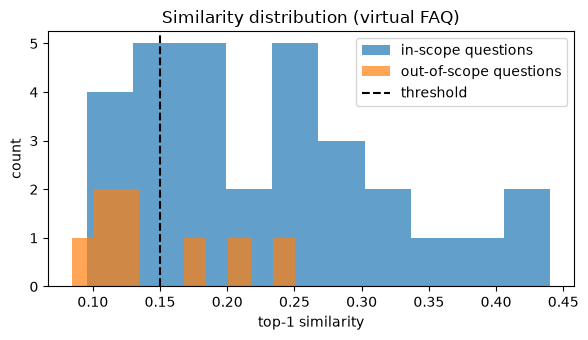

In [10]:
"""오타·구어체 질문과 범위 밖 질문으로 챗봇을 시험하고, 최소 유사도 기준을 바꿔 답변율과 거절율을 비교해 기준을 정한다."""
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

# ---- 공통: 대화 흐름 (인사 -> 의도 분류 -> 되묻기/모름 안내/답변) ----
GREET = ["안녕", "안녕하세요", "반갑", "처음 왔", "전입 왔", "하이"]
THANKS = ["감사", "고마워", "고맙", "수고"]
BYE = ["종료", "그만", "잘 가", "다음에"]
THRESH, MARGIN = 0.15, 0.04      # 최소 유사도, 1·2위 점수 차이 기준
GENERAL_DEPT = "중대 행정반 또는 분대장"


def decide(clf, q, thresh=THRESH, margin=MARGIN):
    """('greet'|'thanks'|'bye'|'answer'|'clarify'|'unknown', 의도, 점수, 후보)"""
    if any(w in q for w in BYE):
        return "bye", None, 0.0, []
    if any(w in q for w in THANKS):
        return "thanks", None, 0.0, []
    top = clf.top(q, 2)
    (i1, s1), (i2, s2) = top[0], top[1]
    if any(w in q for w in GREET) and s1 < 0.25:
        return "greet", None, s1, top
    if s1 < thresh:
        return "unknown", None, s1, top
    if s1 - s2 < margin:
        return "clarify", i1, s1, top
    return "answer", i1, s1, top

clf = TfidfClassifier()
NOISY = [("휴가 신청 어캐함", "leave"), ("점호 몇시임?", "schedule"), ("비번 까먹음ㅠㅠ", "account"), ("외출 몇시까지 가능?", "outing"),
         ("사진 찍어도 됨?", "security"), ("핸드폰 언제 줘요", "phone"), ("밥 몇시에 줌?", "meal"), ("배아파서 약 받고싶음", "medical"),
         ("빨래 어디서 함", "supply"), ("고민 있어서 말하고싶음", "counsel"), ("군복 작아서 바꾸고싶음", "supply"), ("복귀 늦을거같아요ㅜㅜ", "late")]
OUT = ["월급날은 언제예요", "사단장 방문 일정은?", "오늘 날씨 어때요", "전역일이 언제야", "주말에 영화 볼 수 있나요",
       "축구 대회 우승 상품은 뭐예요", "PX 라면 가격은?", "주식 투자 어떻게 해요"]

pn = [clf.predict(q) for q, _ in NOISY]
acc_noisy = np.mean([p[0] == g for p, (_, g) in zip(pn, NOISY)])
rule_noisy = np.mean([rule_classify(q) == g for q, g in NOISY])
print(f"오타·구어체 질문 {len(NOISY)}개 정확도: 규칙 {rule_noisy:.0%}, TF-IDF {acc_noisy:.0%}")
for (q, g), (p, s) in zip(NOISY, pn):
    if p != g:
        print(f"  틀림: {q} -> {INTENT_NAME[p]} ({s:.2f}), 정답 {INTENT_NAME[g]}")

in_scores = [clf.predict(q)[1] for q, _ in TEST]
out_scores = [clf.predict(q)[1] for q in OUT]
rows = []
for th in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    ans = np.mean([s >= th for s in in_scores])
    rej = np.mean([s < th for s in out_scores])
    rows.append({"최소 유사도": th, "범위 안 질문 답변율": ans, "범위 밖 질문 거절율": rej, "합": ans + rej})
df = pd.DataFrame(rows)
best = df.loc[df["합"].idxmax()]
show = df.copy()
for c in ["범위 안 질문 답변율", "범위 밖 질문 거절율"]:
    show[c] = show[c].map(lambda x: f"{x:.0%}")
print("\n" + show.drop(columns="합").to_string(index=False))
print(f"\n두 비율의 합이 가장 큰 기준: {best['최소 유사도']:.2f} (현재 챗봇 기준 {THRESH})")
print("범위 밖인데 답해 버린 질문:", [q for q, s in zip(OUT, out_scores) if s >= THRESH])
print("판단: 기준을 높이면 엉뚱한 답은 줄지만 정상 질문도 모른다고 한다. 범위 밖 질문에는 반드시 담당 부서를 안내한다.")

plt.figure(figsize=(6, 3.5))
plt.hist(in_scores, bins=10, alpha=0.7, label="in-scope questions")
plt.hist(out_scores, bins=10, alpha=0.7, label="out-of-scope questions")
plt.axvline(THRESH, color="k", linestyle="--", label="threshold")
plt.xlabel("top-1 similarity"); plt.ylabel("count"); plt.legend(); plt.title("Similarity distribution (virtual FAQ)")
plt.tight_layout(); plt.show()


---

## 🎯 미션 10. 생활 안내 챗봇 완성하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **모든 기능을 묶은 생활 안내 챗봇을 완성하고 자체 점검합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **질문 정리, 의도 분류, 대화 흐름, 되묻기 후속 응답, 답변 템플릿, 대화 기록을 하나의 챗봇 클래스로 통합하고 정확도·모름 안내·형식·처리 시간 등 자체 점검 항목을 모두 통과시킵니다 과정을 진행하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `챗봇 코드, 대화 예시, 자체 점검 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 통합·완성 — 챗봇을 통합하고 자체 점검을 통과했으며 사람의 확인 절차를 명시했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(챗봇 코드, 대화 예시, 자체 점검 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [11]:
"""질문 정리, TF-IDF 의도 분류, 대화 흐름, 답변 템플릿, 기록을 묶은 '전입 병사 생활 안내 챗봇'을 완성하고 자체 점검한다."""
import re
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 전입 병사 생활 FAQ (실제 부대·규정·인물과 무관)
# 의도 = (코드, 이름, 담당 부서, 답변, 질문 예시 6개). 앞 4개는 학습용, 뒤 2개는 시험용으로 쓴다.
# ---------------------------------------------------------------------------
FAQ = [
    ("schedule", "일과 시간", "중대 행정반",
     "기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.",
     ["하루 일과는 어떻게 되나요", "기상 시간이 몇 시예요", "점호는 몇 시에 하나요", "취침 시간 알려주세요",
      "개인정비 시간은 언제인가요", "아침에 몇 시에 일어나야 해요"]),
    ("leave", "휴가", "중대 행정반",
     "정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.",
     ["휴가는 언제 나갈 수 있나요", "휴가 신청은 어떻게 하나요", "휴가 며칠 전에 신청해야 하나요", "휴가 신청서는 누구에게 내나요",
      "첫 휴가 때 뭘 준비해야 해요", "휴가 인원이 몰리면 어떻게 정해요"]),
    ("outing", "외출·외박", "당직 계통",
     "외출은 주말과 공휴일 09시부터 21시까지입니다. 나가기 전 행선지와 연락처를 당직 계통에 보고합니다.",
     ["외출은 언제 할 수 있나요", "주말에 외출 몇 시까지예요", "외출 나가려면 뭘 보고해야 하나요", "외박은 어떻게 신청해요",
      "공휴일에도 외출 되나요", "외출 때 어디 간다고 말해야 해요"]),
    ("late", "복귀 지연", "당직사관",
     "부득이하게 복귀가 늦어질 것 같으면 복귀 예정 시각 전에 당직사관에게 연락하고 사유를 보고합니다.",
     ["복귀가 늦어질 것 같아요", "차가 막혀서 늦게 들어가면 어떡해요", "복귀 시간에 못 맞추면 누구한테 연락하나요", "늦게 복귀하면 처벌받나요",
      "귀대 시간이 지날 것 같아요", "버스를 놓쳐서 복귀가 늦어요"]),
    ("visit", "면회", "중대 행정반",
     "면회는 주말과 공휴일 오후에 면회실에서 할 수 있습니다. 가족이 방문하기 전 분대장을 통해 면회 신청을 해 두세요.",
     ["가족이 면회 오려면 어떻게 해요", "면회는 언제 가능한가요", "면회 신청은 어디서 하나요", "부모님이 오시는데 면회 되나요",
      "면회 장소가 어디예요", "친구도 면회 올 수 있나요"]),
    ("phone", "휴대전화·전화", "중대 행정반",
     "휴대전화는 평일 18시부터 21시, 주말과 공휴일 09시부터 21시에 사용할 수 있습니다. 사용 시간 외에는 지정 장소에 보관합니다.",
     ["휴대전화는 언제 쓸 수 있나요", "핸드폰 사용 시간이 어떻게 되나요", "가족에게 전화하고 싶은데 언제 가능해요", "폰 반납은 언제 해요",
      "평일에도 전화할 수 있나요", "휴대폰 보관은 어디에 하나요"]),
    ("welfare", "복지시설", "복지 담당",
     "PX와 체력단련실은 개인정비 시간과 주말에 이용합니다. 시설 소독·점검 시간에는 이용이 제한됩니다.",
     ["PX는 몇 시에 여나요", "체력단련실은 언제 쓸 수 있어요", "복지시설 이용 시간이 궁금해요", "PX에서 뭘 살 수 있나요",
      "운동하려면 어디로 가야 해요", "도서관은 언제 열어요"]),
    ("meal", "식사", "취사 담당",
     "식사는 아침 07시, 점심 12시, 저녁 18시에 식당에서 합니다. 근무나 훈련으로 시간을 맞출 수 없으면 분대장에게 알려 별도 배식을 받습니다.",
     ["식사 시간은 언제예요", "아침 밥은 몇 시에 먹나요", "근무 때문에 식사를 못 하면 어떻게 해요", "식당 위치가 어디예요",
      "저녁 식사는 몇 시부터인가요", "점심은 몇 시에 나와요"]),
    ("medical", "진료·의무", "의무실",
     "몸이 아프면 분대장에게 알리고 의무실에서 진료를 받습니다. 부상자나 환자가 생기면 즉시 당직 계통과 의무실에 알립니다.",
     ["몸이 아픈데 어떻게 해요", "의무실은 어디에 있나요", "다쳤을 때는 어디에 말해요", "감기 걸리면 진료받을 수 있나요",
      "병원에 가야 할 것 같아요", "예방접종은 언제 하나요"]),
    ("security", "보안·촬영", "보안 담당",
     "부대 안에서 휴대전화로 시설·문서·화면을 촬영하거나 외부로 전송하는 일은 금지입니다. 부대 자료를 외부 AI 서비스에 입력하는 것도 안 됩니다.",
     ["부대에서 사진 찍어도 되나요", "생활관 모습을 SNS에 올려도 되나요", "부대 자료를 AI에 넣어도 되나요", "촬영하면 안 되는 곳이 있나요",
      "휴대폰 카메라 써도 돼요", "ChatGPT에 부대 문서를 입력해도 되나요"]),
    ("account", "계정·비밀번호", "정보보호 담당",
     "업무용 계정 비밀번호는 분기마다 바꾸고 영문·숫자·특수문자를 섞어 9자리 이상으로 만듭니다. 비밀번호는 남에게 알려 주지 않습니다.",
     ["비밀번호는 몇 자리로 만들어요", "비번 바꾸는 주기가 어떻게 돼요", "계정 비밀번호를 잊어버렸어요", "비밀번호 규칙이 뭐예요",
      "전우에게 내 비번을 알려줘도 되나요", "업무 계정은 어떻게 받아요"]),
    ("selfdev", "자기개발", "정훈교육 담당",
     "자격증 응시료와 온라인 강좌 수강료는 연간 한도 안에서 실비로 지원합니다. 신청할 때 증빙 서류를 함께 냅니다.",
     ["자격증 시험 응시료 지원되나요", "온라인 강의 들을 수 있나요", "자기개발 지원은 어떻게 신청해요", "한국사 시험 보고 싶어요",
      "수강료도 지원해 주나요", "자격증 공부는 언제 할 수 있어요"]),
    ("counsel", "고충·상담", "병영생활상담관",
     "고충이나 건의는 소원수리함, 중대장 면담, 상담관 상담으로 말할 수 있고 이로 인한 불이익은 없습니다.",
     ["힘든 일이 있으면 어디에 말해요", "상담받고 싶은데 어떻게 해요", "선임과 문제가 생겼어요", "건의사항은 어디에 내요",
      "소원수리함이 어디 있어요", "고민을 털어놓을 사람이 필요해요"]),
    ("room", "생활관·청소", "분대장",
     "생활관 청소는 매일 아침 점호 후 20분간 합니다. 개인 전열기는 사용할 수 없고, 난방기 이상은 행정반에 신고합니다.",
     ["청소는 언제 하나요", "생활관에서 전기난로 써도 되나요", "청소 구역은 누가 정해요", "난방기가 고장 났어요",
      "생활관 정리 기준이 뭐예요", "방 청소 몇 분 동안 해요"]),
    ("supply", "보급품·세탁", "군수 담당",
     "피복과 개인 보급품은 전입 첫 주에 군수 담당에게 수령하고, 사이즈가 맞지 않으면 분대장을 통해 교환을 신청합니다. 세탁은 지정된 세탁 시간에 합니다.",
     ["군복 사이즈가 안 맞아요", "보급품은 어디서 받아요", "빨래는 어떻게 해요", "전투화를 교환하고 싶어요",
      "세탁실은 언제 쓸 수 있나요", "속옷이나 양말도 보급되나요"]),
]
INTENT_IDS = [f[0] for f in FAQ]
INTENT_NAME = {f[0]: f[1] for f in FAQ}
DEPT = {f[0]: f[2] for f in FAQ}
ANSWER = {f[0]: f[3] for f in FAQ}
TRAIN = [(q, f[0]) for f in FAQ for q in f[4][:4]]   # 60개
TEST = [(q, f[0]) for f in FAQ for q in f[4][4:]]    # 30개

# ---- 공통: 질문 정리, 규칙 기반 분류기, TF-IDF 분류기, 평가 ----
STOPWORDS = ["언제까지", "몇 시에", "어디서", "어디에", "어떻게", "어떡해요", "알려주세요", "궁금해요", "되나요", "하나요", "있나요",
             "언제", "어디", "몇 시", "돼요", "해요", "뭐예요", "수 있", "같아요", "주세요", "해야"]


def normalize(q):
    """웃음·특수문자 제거, 문장 끝 어미와 질문 투 말(언제·어떻게 등) 제거"""
    q = re.sub(r"[ㅋㅎㅠㅜ]+|[!?~.,]+", " ", q)
    for w in sorted(STOPWORDS, key=len, reverse=True):
        q = q.replace(w, " ")
    return re.sub(r"\s+", " ", q).strip()


RULES = {   # [교육용가상자료] 의도별 핵심 키워드 (Baseline)
    "schedule": ["일과", "점호", "취침", "시간"], "leave": ["휴가"], "outing": ["외출", "외박"],
    "late": ["복귀", "늦"], "visit": ["면회"], "phone": ["휴대전화", "핸드폰", "전화"],
    "welfare": ["PX", "체력단련"], "meal": ["식사", "식당"], "medical": ["아프", "의무실"],
    "security": ["촬영", "사진"], "account": ["비밀번호", "비번"], "selfdev": ["자격증", "응시료"],
    "counsel": ["상담", "고충"], "room": ["청소", "난방"], "supply": ["군복", "빨래"],
}


def rule_classify(q):
    best, best_n = None, 0
    for intent, kws in RULES.items():
        n = sum(k in q for k in kws)
        if n > best_n:
            best, best_n = intent, n
    return best          # 맞는 키워드가 없으면 None


class TfidfClassifier:
    """의도마다 '이름 + 답변 + 학습 질문 4개'를 한 문서로 묶고, 질문과 가장 비슷한 의도 문서를 찾는다."""
    def __init__(self, faq=None, n_train=4):
        faq = faq or FAQ
        self.ids = [f[0] for f in faq]
        self.docs = [normalize(f[1] + " " + f[3] + " " + " ".join(f[4][:n_train])) for f in faq]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3), sublinear_tf=True).fit(self.docs)
        self.D = self.vec.transform(self.docs)

    def scores(self, q):
        s = cosine_similarity(self.vec.transform([normalize(q)]), self.D).ravel()
        return dict(zip(self.ids, (float(x) for x in s)))

    def top(self, q, k=2):
        return sorted(self.scores(q).items(), key=lambda x: -x[1])[:k]

    def predict(self, q):
        return self.top(q, 1)[0]


def accuracy(pred, gold):
    return float(np.mean([p == g for p, g in zip(pred, gold)]))

# ---- 공통: 대화 흐름 (인사 -> 의도 분류 -> 되묻기/모름 안내/답변) ----
GREET = ["안녕", "안녕하세요", "반갑", "처음 왔", "전입 왔", "하이"]
THANKS = ["감사", "고마워", "고맙", "수고"]
BYE = ["종료", "그만", "잘 가", "다음에"]
THRESH, MARGIN = 0.15, 0.04      # 최소 유사도, 1·2위 점수 차이 기준
GENERAL_DEPT = "중대 행정반 또는 분대장"


def decide(clf, q, thresh=THRESH, margin=MARGIN):
    """('greet'|'thanks'|'bye'|'answer'|'clarify'|'unknown', 의도, 점수, 후보)"""
    if any(w in q for w in BYE):
        return "bye", None, 0.0, []
    if any(w in q for w in THANKS):
        return "thanks", None, 0.0, []
    top = clf.top(q, 2)
    (i1, s1), (i2, s2) = top[0], top[1]
    if any(w in q for w in GREET) and s1 < 0.25:
        return "greet", None, s1, top
    if s1 < thresh:
        return "unknown", None, s1, top
    if s1 - s2 < margin:
        return "clarify", i1, s1, top
    return "answer", i1, s1, top

# ---- 공통: 답변 템플릿 ----
CLOSING = "더 궁금한 점은 {dept}에 확인하세요. (이 안내는 교육용 가상 자료입니다)"
TEMPLATES = {
    "greet": "안녕하세요, 한빛대대 전입 병사 생활 안내 챗봇입니다. 일과, 휴가, 외출, 복지시설, 의무, 보안 등을 물어보세요.",
    "thanks": "도움이 되었다면 다행입니다. 다른 질문이 있으면 편하게 물어보세요.",
    "bye": "안내를 마칩니다. 확인이 필요한 내용은 분대장과 행정반에 문의하세요.",
    "answer": "[{name}] {answer}\n{closing}",
    "clarify": "'{q}'는 [{n1}]과 [{n2}] 중 어느 쪽이 궁금한가요? 한 가지를 골라 다시 물어봐 주세요.",
    "unknown": "질문에 맞는 안내를 찾지 못했습니다. 이 내용은 " + GENERAL_DEPT + "에게 확인해 주세요.",
}


def respond(clf, q, thresh=THRESH, margin=MARGIN):
    kind, intent, score, top = decide(clf, q, thresh, margin)
    if kind in ("greet", "thanks", "bye"):
        return kind, None, TEMPLATES[kind]
    if kind == "unknown":
        return kind, None, TEMPLATES["unknown"]
    if kind == "clarify":
        return kind, intent, TEMPLATES["clarify"].format(q=q, n1=INTENT_NAME[top[0][0]], n2=INTENT_NAME[top[1][0]])
    text = TEMPLATES["answer"].format(name=INTENT_NAME[intent], answer=ANSWER[intent],
                                      closing=CLOSING.format(dept=DEPT[intent]))
    return kind, intent, text


class LifeGuideBot:
    def __init__(self, thresh=THRESH, margin=MARGIN):   # 미션 9에서 정한 기준
        self.clf = TfidfClassifier()
        self.thresh, self.margin = thresh, margin
        self.pending = None       # 되묻기 후 사용자의 선택을 기다리는 두 의도
        self.log = []

    def ask(self, q):
        if self.pending:          # 직전에 되물었다면, 두 후보 중 어느 쪽인지 답을 해석한다
            cand, self.pending = self.pending, None
            sc = self.clf.scores(q)
            best = max(cand, key=lambda i: sc[i])
            if sc[best] > 0:
                text = TEMPLATES["answer"].format(name=INTENT_NAME[best], answer=ANSWER[best], closing=CLOSING.format(dept=DEPT[best]))
                self.log.append({"q": q, "kind": "answer", "intent": best})
                return "answer", best, text
        kind, intent, text = respond(self.clf, q, self.thresh, self.margin)
        if kind == "clarify":
            top = self.clf.top(q, 2)
            self.pending = (top[0][0], top[1][0])
        self.log.append({"q": q, "kind": kind, "intent": intent})
        return kind, intent, text


bot = LifeGuideBot()
for q in ["안녕하세요", "휴가 신청 어캐함", "개인정비 시간은 언제인가요", "일과가 궁금해요", "사단장 방문 일정은?", "고맙습니다", "종료"]:
    kind, intent, text = bot.ask(q)
    print(f"병사: {q}\n챗봇({kind}): {text}\n")

# ---- 자체 점검 ----
t0 = time.perf_counter()
res = [LifeGuideBot().ask(q) for q, _ in TEST]
ms = (time.perf_counter() - t0) / len(TEST) * 1000
gold = [g for _, g in TEST]
acc = np.mean([r[1] == g for r, g in zip(res, gold)])
base = accuracy([rule_classify(q) for q, _ in TEST], gold)
OUT = ["월급날은 언제예요", "사단장 방문 일정은?", "오늘 날씨 어때요", "전역일이 언제야", "주말에 영화 볼 수 있나요",
       "축구 대회 우승 상품은 뭐예요", "PX 라면 가격은?", "주식 투자 어떻게 해요"]
refused = np.mean([LifeGuideBot().ask(q)[0] == "unknown" for q in OUT])
manners = [LifeGuideBot().ask(q)[0] for q in ["안녕하세요", "고맙습니다", "종료"]] == ["greet", "thanks", "bye"]
b2 = LifeGuideBot(); b2.ask("개인정비 시간은 언제인가요"); follow = b2.ask("일과가 궁금해요")
answers = [r for r in res if r[0] == "answer"]
checks = {"시험 질문 올바른 답변 비율 65% 이상(되묻기·모름은 오답)": acc >= 0.65, "규칙 Baseline보다 정확도 높음": acc > base,
          "범위 밖 질문 60% 이상 모름 안내": refused >= 0.6, "인사·감사·종료 응답": manners,
          "되묻기 후 선택 응답으로 의도 확정": follow[0] == "answer" and follow[1] == "schedule",
          "모든 답변에 담당 부서 안내": all(DEPT[r[1]] in r[2] for r in answers), "질문당 처리 100ms 이내": ms < 100,
          "대화 기록 저장": len(bot.log) >= 7}
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print(f"자체 점검 {sum(checks.values())}/{len(checks)} 통과 (정확도 {acc:.0%}, Baseline {base:.0%}, 범위 밖 모름 {refused:.0%}, 질문당 {ms:.1f} ms)")
print("\n※ 이 챗봇은 가상 자료로 만든 학습용이다. 실제 휴가·외출·보안 등의 기준은 분대장·행정반 등 담당 부서와 지휘계통의 확인을 따른다.")


병사: 안녕하세요
챗봇(greet): 안녕하세요, 한빛대대 전입 병사 생활 안내 챗봇입니다. 일과, 휴가, 외출, 복지시설, 의무, 보안 등을 물어보세요.

병사: 휴가 신청 어캐함
챗봇(answer): [휴가] 정기 휴가는 시행 7일 전까지 휴가 신청서를 써서 분대장을 거쳐 중대장에게 제출합니다. 같은 기간 신청자가 많으면 중대장이 조정합니다.
더 궁금한 점은 중대 행정반에 확인하세요. (이 안내는 교육용 가상 자료입니다)

병사: 개인정비 시간은 언제인가요
챗봇(clarify): '개인정비 시간은 언제인가요'는 [일과 시간]과 [복지시설] 중 어느 쪽이 궁금한가요? 한 가지를 골라 다시 물어봐 주세요.

병사: 일과가 궁금해요
챗봇(answer): [일과 시간] 기상은 06시 30분, 점호는 21시 30분, 취침은 22시입니다. 평일 18시부터 21시까지는 개인정비 시간입니다.
더 궁금한 점은 중대 행정반에 확인하세요. (이 안내는 교육용 가상 자료입니다)

병사: 사단장 방문 일정은?
챗봇(unknown): 질문에 맞는 안내를 찾지 못했습니다. 이 내용은 중대 행정반 또는 분대장에게 확인해 주세요.

병사: 고맙습니다
챗봇(thanks): 도움이 되었다면 다행입니다. 다른 질문이 있으면 편하게 물어보세요.

병사: 종료
챗봇(bye): 안내를 마칩니다. 확인이 필요한 내용은 분대장과 행정반에 문의하세요.

[PASS] 시험 질문 올바른 답변 비율 65% 이상(되묻기·모름은 오답)
[PASS] 규칙 Baseline보다 정확도 높음
[PASS] 범위 밖 질문 60% 이상 모름 안내
[PASS] 인사·감사·종료 응답
[PASS] 되묻기 후 선택 응답으로 의도 확정
[PASS] 모든 답변에 담당 부서 안내
[PASS] 질문당 처리 100ms 이내
[PASS] 대화 기록 저장
자체 점검 8/8 통과 (정확도 70%, Baseline 43%, 범위 밖 모름 62%, 질문당 8.6 ms)

※ 이 챗봇은 가상 자료로 만든 학습용이다. 실제 휴가·외출·보안 등의 기준은